In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def otsu_explicit(image):
    # 1. Calculate histogram and probabilities
    hist, _ = np.histogram(image.flatten(), bins=256, range=[0, 256])
    total_pixels = image.size
    probabilities = hist / total_pixels
    
    min_variance = float('inf')
    optimal_threshold = 0
    
    # 2. Iterate through all possible thresholds k
    for k in range(256):
        # Probabilities of class 0 (background) and class 1 (foreground)
        p0 = probabilities[:k+1]
        p1 = probabilities[k+1:]
        
        w0 = np.sum(p0)
        w1 = np.sum(p1)
        
        # Skip if a class has no pixels
        if w0 == 0 or w1 == 0:
            continue
            
        # Intensity values
        i0 = np.arange(0, k+1)
        i1 = np.arange(k+1, 256)
        
        # Means for each class 
        mu0 = np.sum(i0 * p0) / w0
        mu1 = np.sum(i1 * p1) / w1
        
        # Variances for each class 
        var0 = np.sum(((i0 - mu0) ** 2) * p0) / w0
        var1 = np.sum(((i1 - mu1) ** 2) * p1) / w1
        
        # Within-class variance
        within_class_variance = w0 * var0 + w1 * var1
        
        # Check if this is the minimum variance
        if within_class_variance < min_variance:
            min_variance = within_class_variance
            optimal_threshold = k
            
    # Apply threshold
    binary_image = (image > optimal_threshold).astype(np.uint8) * 255
    return optimal_threshold, binary_image


img = cv2.imread('euros_nv.jpg', cv2.IMREAD_GRAYSCALE)
if img is not None:
    thresh_val, segmented_img = otsu_explicit(img)
    print(f"Optimal Threshold (Explicit): {thresh_val}")

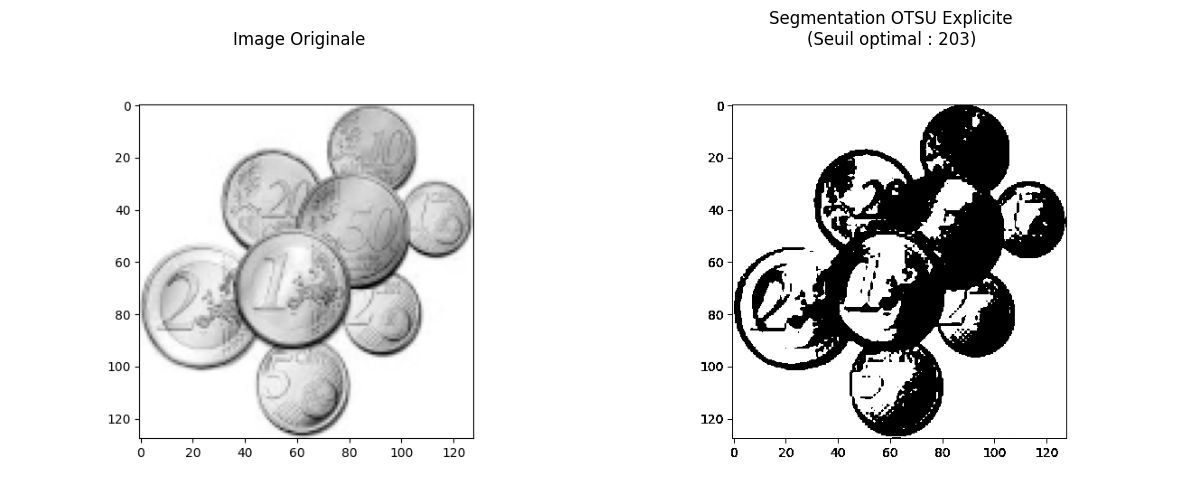

In [10]:
import cv2
import matplotlib.pyplot as plt

path= "euros_nv.png"
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is not None:
   
    thresh_val, segmented_img = otsu_explicit(img)
    
   
    plt.figure(figsize=(12, 6)) 
    
   
    plt.subplot(1, 2, 1) # 
    plt.imshow(img, cmap='gray')
    plt.title('Image Originale')
    plt.axis('off') # Masquer les axes
    
    
    plt.subplot(1, 2, 2) 
    plt.imshow(segmented_img, cmap='gray')
    plt.title(f'Segmentation OTSU Explicite\n(Seuil optimal : {thresh_val})')
    plt.axis('off')
    
   
    plt.tight_layout()
    plt.show()

else:
    print("Erreur : Impossible de charger l'image. Vérifiez le chemin du fichier.")

Calcul de la segmentation Gaussienne en cours... 


C:\Users\pc\AppData\Roaming\Python\Python310\site-packages\sklearn\mixture\_gaussian_mixture.py:487: RuntimeWarning: invalid value encountered in cast
  log_prob[:, k] = np.sum(np.square(y), axis=1)


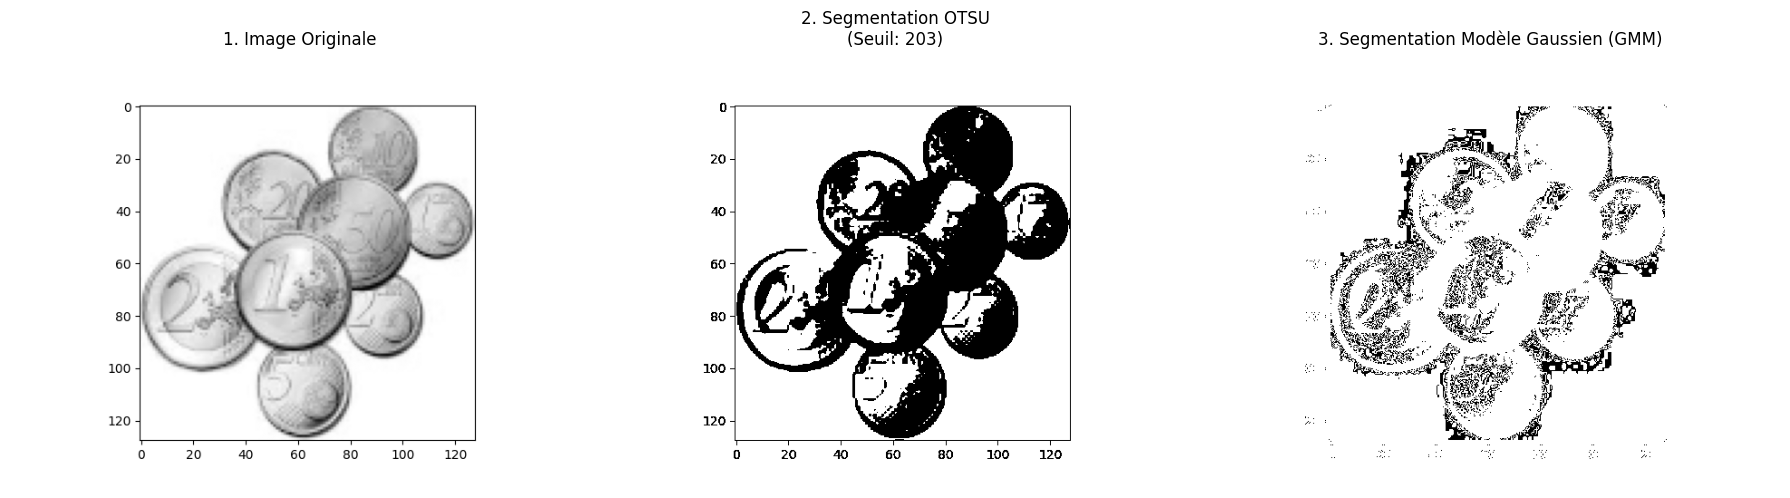

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# --- Fonction de Segmentation Gaussienne (GMM) ---
def gaussian_segmentation(image):
    
    data = image.flatten().reshape(-1, 1)
    
    
    gmm = GaussianMixture(n_components=2, random_state=42)
    gmm.fit(data)
    
    
    labels = gmm.predict(data)
    
    segmented_img = labels.reshape(image.shape)
    
   
    if gmm.means_[0][0] > gmm.means_[1][0]:
        segmented_img = 1 - segmented_img
        
    return (segmented_img * 255).astype(np.uint8)


img = cv2.imread('euros_nv.png', cv2.IMREAD_GRAYSCALE)

if img is not None:
    
    ret, otsu_img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    
    print("Calcul de la segmentation Gaussienne en cours... ")
    gaussian_img = gaussian_segmentation(img)
    
    # --- Affichage Comparatif ---
    plt.figure(figsize=(18, 6)) 
    
    # Image Originale
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('1. Image Originale')
    plt.axis('off')
    
    # Résultat OTSU
    plt.subplot(1, 3, 2) # 
    plt.imshow(otsu_img, cmap='gray')
    plt.title(f'2. Segmentation OTSU\n(Seuil: {int(ret)})')
    plt.axis('off')
    
   
    plt.subplot(1, 3, 3) 
    plt.imshow(gaussian_img, cmap='gray')
    plt.title('3. Segmentation Modèle Gaussien (GMM)')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

else:
    print("Erreur : Impossible de charger l'image.")

Calcul de la segmentation Gaussienne en cours... 


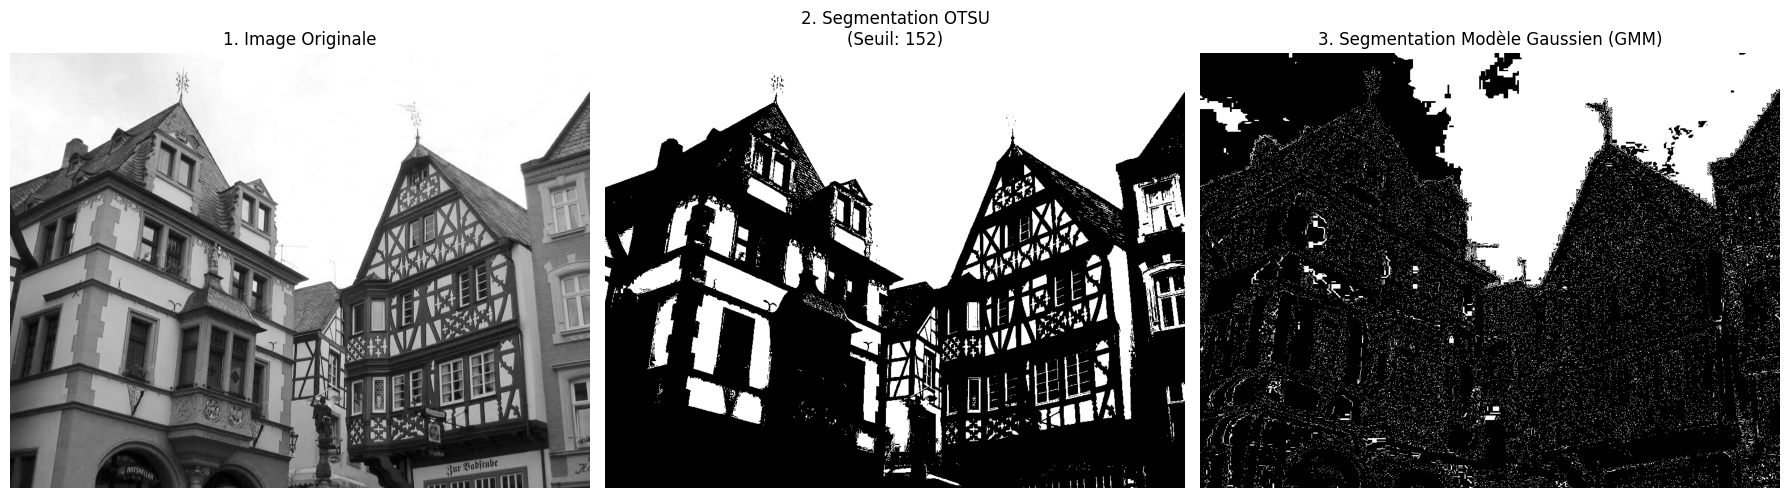

In [24]:

img = cv2.imread('image_otsu.jpg', cv2.IMREAD_GRAYSCALE)

if img is not None:
    
    ret, otsu_img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    
    print("Calcul de la segmentation Gaussienne en cours... ")
    gaussian_img = gaussian_segmentation(img)
    
    # --- Affichage Comparatif ---
    plt.figure(figsize=(18, 6)) 
    
    # Image Originale
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('1. Image Originale')
    plt.axis('off')
    
    # Résultat OTSU
    plt.subplot(1, 3, 2) # 
    plt.imshow(otsu_img, cmap='gray')
    plt.title(f'2. Segmentation OTSU\n(Seuil: {int(ret)})')
    plt.axis('off')
    
   
    plt.subplot(1, 3, 3) 
    plt.imshow(gaussian_img, cmap='gray')
    plt.title('3. Segmentation Modèle Gaussien (GMM)')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

else:
    print("Erreur : Impossible de charger l'image.")

--- COMPARAISON DES SEUILS ---
Seuil OTSU Explicite (Q1) : 203
Seuil OTSU OpenCV         : 203
-> Conclusion : Les résultats sont strictement identiques !


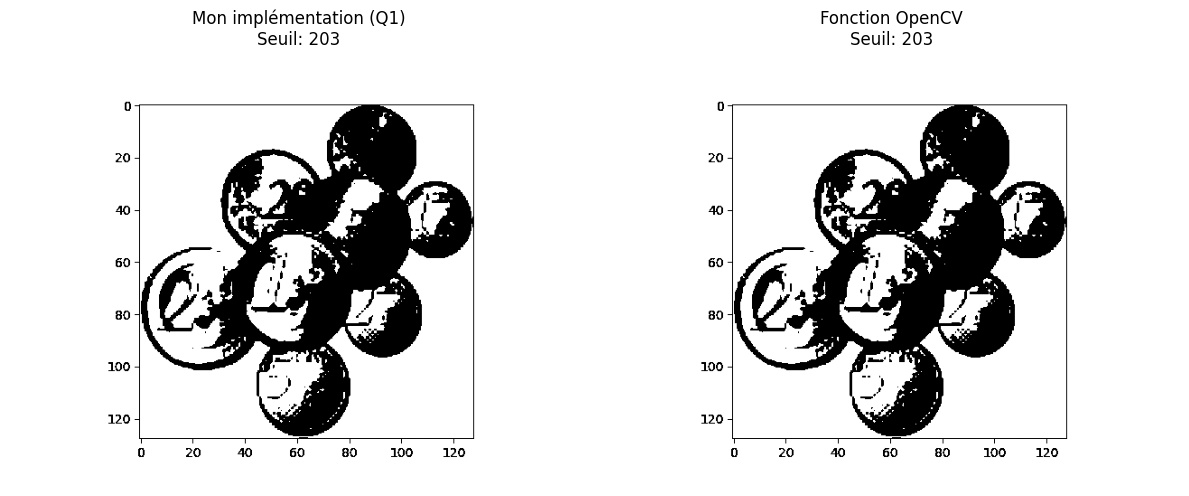

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread('euros_nv.png', cv2.IMREAD_GRAYSCALE)

if img is not None:
    # --- 3. Exécution des deux méthodes ---
    # A. Votre méthode (Q1)
    thresh_custom, img_custom = otsu_explicit(img)
    
    # B. Méthode OpenCV (cv2.THRESH_OTSU)
    thresh_cv2, img_cv2 = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    
    print(f"--- COMPARAISON DES SEUILS ---")
    print(f"Seuil OTSU Explicite (Q1) : {thresh_custom}")
    print(f"Seuil OTSU OpenCV         : {int(thresh_cv2)}")
    
    if thresh_custom == int(thresh_cv2):
        print("-> Conclusion : Les résultats sont strictement identiques !")
    else:
        print("-> Conclusion : Les résultats sont légèrement différents (voir explication théorique).")

    
    plt.figure(figsize=(12, 6))
    
    # Image Q1
    plt.subplot(1, 2, 1)
    plt.imshow(img_custom, cmap='gray')
    plt.title(f'Mon implémentation (Q1)\nSeuil: {thresh_custom}')
    plt.axis('off')
    
    # Image OpenCV
    plt.subplot(1, 2, 2)
    plt.imshow(img_cv2, cmap='gray')
    plt.title(f'Fonction OpenCV\nSeuil: {int(thresh_cv2)}')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

else:
    print("Erreur : Impossible de charger l'image.")

Running optimized approach...
Optimal Threshold Found: 203
Execution Time: 0.02006 seconds


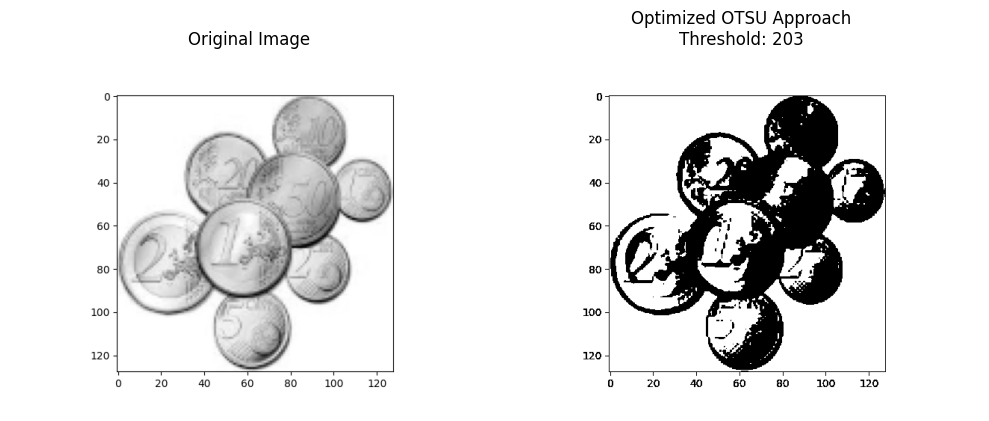

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

def otsu_optimized_approach(image):
    
    hist, _ = np.histogram(image.flatten(), bins=256, range=[0, 256])
    total_pixels = image.size
    
    
    sum_total = np.dot(np.arange(256), hist)
    
    
    weight_background = 0.0
    sum_background = 0.0
    
    max_variance = 0.0
    optimal_threshold = 0
    
    
    for k in range(256):
        
        weight_background += hist[k]
        if weight_background == 0:
            continue
            
        
        weight_foreground = total_pixels - weight_background
        if weight_foreground == 0:
            break 
            
        
        sum_background += k * hist[k]
        
        
        mean_background = sum_background / weight_background
        mean_foreground = (sum_total - sum_background) / weight_foreground
        
        
        between_class_variance = weight_background * weight_foreground * ((mean_background - mean_foreground) ** 2)
        
        
        if between_class_variance > max_variance:
            max_variance = between_class_variance
            optimal_threshold = k
            
    
    binary_image = (image > optimal_threshold).astype(np.uint8) * 255
    return optimal_threshold, binary_image


img = cv2.imread('euros_nv.png', cv2.IMREAD_GRAYSCALE)

if img is not None:
    print("Running optimized approach...")
    
    
    start_time = time.time()
    optimal_thresh, segmented_img = otsu_optimized_approach(img)
    end_time = time.time()
    
    print(f"Optimal Threshold Found: {optimal_thresh}")
    print(f"Execution Time: {end_time - start_time:.5f} seconds")
    
    
    plt.figure(figsize=(10, 5))
    
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(segmented_img, cmap='gray')
    plt.title(f'Optimized OTSU Approach\nThreshold: {optimal_thresh}')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

else:
    print("Error: Could not load the image.")